# Task 2: Generation mix, curtailment and storage

Stacked area chart of generation by generator, with total load as a dashed line. After that, an explanation of when Frankfurt Gas runs, where curtailment happens, and what storage would add.

In [1]:
import logging, warnings
import pandas as pd
import matplotlib.pyplot as plt
import pypsa

warnings.filterwarnings("ignore")
logging.getLogger("pypsa").setLevel(logging.ERROR)
logging.getLogger("linopy").setLevel(logging.ERROR)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
SOLVER = "highs"  # free solver, installed with: pip install highspy

In [2]:
def load_network():
    """Meshed AC-DC example, exactly as in the PyPSA documentation."""
    n = pypsa.examples.ac_dc_meshed()
    n.links.loc["Norwich Converter", "p_nom_extendable"] = False
    return n

def total_cost(n):
    return n.objective + n.objective_constant

n = load_network()
n.optimize(solver_name=SOLVER, log_to_console=False)

('ok', 'optimal')

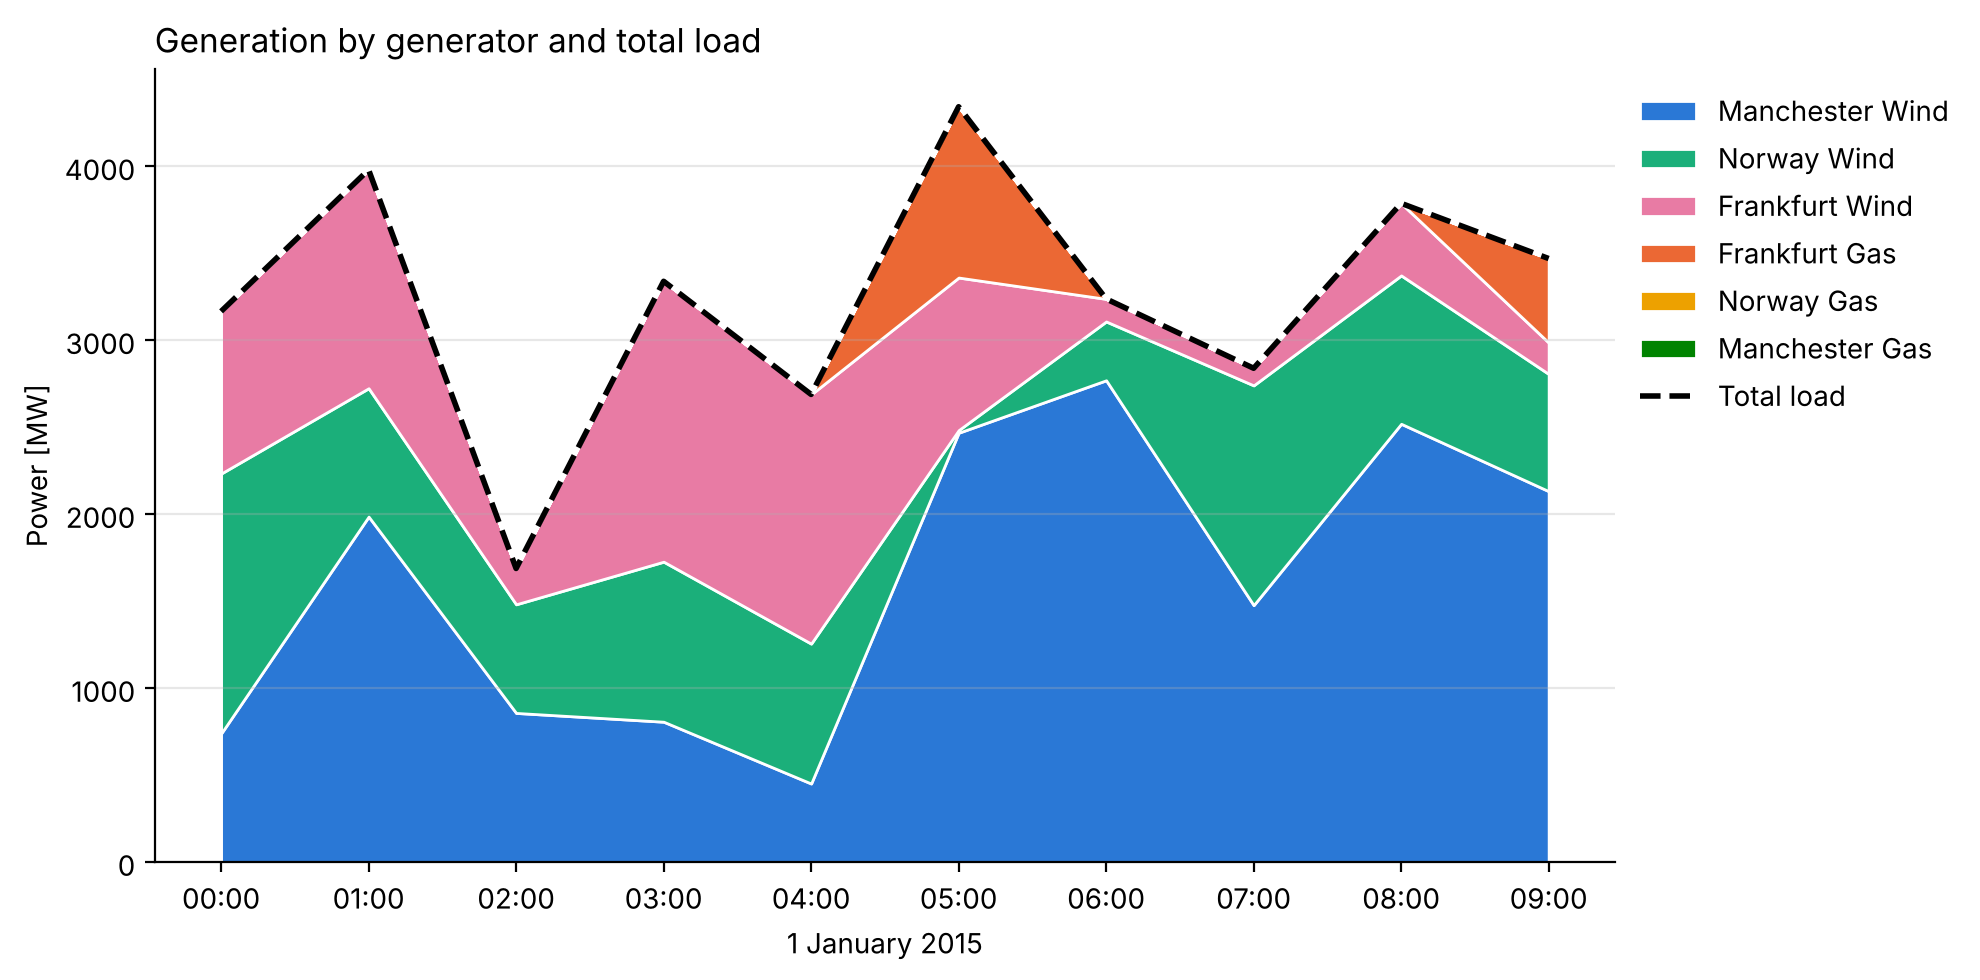

In [3]:
COLORS = {  # fixed order, one colour per generator
    "Manchester Wind": "#2a78d6", "Norway Wind": "#1baf7a", "Frankfurt Wind": "#e87ba4",
    "Frankfurt Gas": "#eb6834", "Norway Gas": "#eda100", "Manchester Gas": "#008300",
}

def stacked_plot(n, title):
    gen = n.generators_t.p.clip(lower=0)[list(COLORS)]
    load = n.loads_t.p_set.sum(axis=1)
    x = gen.index.strftime("%H:%M")
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.stackplot(range(len(x)), gen.T.values, labels=gen.columns,
                 colors=[COLORS[c] for c in gen.columns], edgecolor="white", linewidth=1)
    ax.plot(range(len(x)), load.values, "k--", lw=2, label="Total load")
    ax.set_xticks(range(len(x)), x)
    ax.set_xlabel("1 January 2015")
    ax.set_ylabel("Power [MW]")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    plt.tight_layout()
    return fig, ax

stacked_plot(n, "Generation by generator and total load")
plt.show()

Manchester Gas and Norway Gas are in the legend but produce nothing, because they are built at 0 MW (see Task 1). Generation and load match in every hour. Line losses are not modelled, so generation equals load exactly.

In [4]:
print("Frankfurt Gas output [MW]:")
print(n.generators_t.p["Frankfurt Gas"].round(1))
print(f"\nTotal gas energy: {n.generators_t.p['Frankfurt Gas'].sum():.1f} MWh")
print(f"CO2 emitted: {n.generators_t.p['Frankfurt Gas'].sum() / n.generators.efficiency['Frankfurt Gas'] * 0.24:.1f} t (cap = 1000 t)")

Frankfurt Gas output [MW]:
snapshot
2015-01-01 00:00:00     -0.0
2015-01-01 01:00:00     -0.0
2015-01-01 02:00:00     -0.0
2015-01-01 03:00:00     -0.0
2015-01-01 04:00:00     -0.0
2015-01-01 05:00:00    982.0
2015-01-01 06:00:00     -0.0
2015-01-01 07:00:00     -0.0
2015-01-01 08:00:00     -0.0
2015-01-01 09:00:00    483.2
Name: Frankfurt Gas, dtype: float64

Total gas energy: 1465.3 MWh
CO2 emitted: 1000.0 t (cap = 1000 t)


## 2.1 Why Frankfurt Gas only runs in 2 of the 10 hours

Two things together explain this.

1. **Gas is very expensive once the CO2 cap is priced in.** The cap of 1000 t is binding, and its shadow price is about 2,180 EUR/t. That adds roughly 1,490 EUR/MWh to the 4 EUR/MWh fuel cost of gas. Wind has almost no running cost, so gas only runs when the wind fleet physically cannot meet demand.
2. **There are only two such hours.** The table below compares, for every hour, the wind that is available (`p_max_pu` times the built capacity) with the load. Only at **05:00** (peak load with almost no wind in Norway) and **09:00** (low wind in Frankfurt) is available wind below load. In every other hour wind can cover the full demand.

The optimiser could build even more wind so that gas is not needed at all, but adding wind capacity only to cover one or two hours costs more than burning the gas that the CO2 cap still allows. The total gas output, about 1,465 MWh, uses up the 1000 t budget exactly. Gas is used as far as the cap allows and no further.

The nodal prices show the same thing. In hours with surplus wind, the price is 0.11 EUR/MWh, which is the running cost of Manchester Wind. In the two gas hours it jumps to about 1,490 to 1,590 EUR/MWh.

In [5]:
wind = n.generators.index[n.generators.carrier == "wind"]
avail = n.generators_t.p_max_pu[wind] * n.generators.p_nom_opt[wind]
summary = pd.DataFrame({
    "load": n.loads_t.p_set.sum(axis=1),
    "wind_available": avail.sum(axis=1),
    "wind_dispatched": n.generators_t.p[wind].sum(axis=1),
    "gas": n.generators_t.p["Frankfurt Gas"],
    "price_avg": n.buses_t.marginal_price.mean(axis=1),
})
summary["wind_minus_load"] = summary.wind_available - summary.load
summary["curtailment"] = summary.wind_available - summary.wind_dispatched
summary.index = summary.index.strftime("%H:%M")
summary.round(1)

,load,wind_available,wind_dispatched,gas,price_avg,wind_minus_load,curtailment
snapshot,,,,,,,
00:00,3167.0,6231.5,3167.0,-0.0,0.1,3064.6,3064.6
01:00,3980.9,3980.9,3980.9,-0.0,1421.8,0.0,0.0
02:00,1688.8,1786.4,1688.8,-0.0,0.1,97.6,97.6
03:00,3340.1,3586.1,3340.1,-0.0,0.1,246.0,246.0
04:00,2689.4,4801.5,2689.4,-0.0,0.1,2112.0,2112.0
05:00,4343.6,3361.6,3361.6,982.0,1593.6,-982.0,0.0
06:00,3238.8,3245.3,3238.8,-0.0,0.6,6.4,6.4
07:00,2840.0,2840.0,2840.0,-0.0,1006.9,-0.0,0.0
08:00,3788.2,3810.4,3788.2,-0.0,0.3,22.2,22.2


## 2.2 Curtailment

Curtailment is wind that could have been produced but was not used: available output minus dispatched output. In the model it happens in **6 of the 10 hours** (00:00, 02:00, 03:00, 04:00, 06:00, 08:00). It totals about **5,550 MWh, about 15% of the available wind energy**, and all of it is at **Manchester Wind**. The largest amounts are at 00:00 (about 3,060 MW) and 04:00 (about 2,110 MW), when Manchester wind is strong and demand is moderate.

The reason is the build decision. Manchester Wind is sized at about 4.1 GW so that it can carry the system through 05:00 and 06:00, when Norway and Frankfurt have little wind. In windy, low-demand hours that same capacity produces more than the system can use or move. At 00:00, for example, the line and converter limits stop the surplus from reaching other buses.

In the real world, curtailment would occur in the same kinds of hours:

* **Night and early morning with strong wind and low demand** (00:00 to 04:00 here).
* **When the grid is congested**. Examples are north to south flows in Great Britain (the Scotland to England boundary) and in Germany (north German wind that cannot reach the south). In this model the UK lines and the Bremen-Frankfurt line play that role.
* **When inflexible plants must stay on**, such as must-run thermal units or plants providing system services. The model does not include these, so real curtailment would usually be higher.

Curtailed hours are visible in the model as hours where the nodal price drops to the marginal cost of wind (about 0.1 EUR/MWh).

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


name      Manchester Wind  Norway Wind  Frankfurt Wind
snapshot                                              
00:00              3064.6          0.0             0.0
01:00                 0.0          0.0             0.0
02:00                97.6          0.0             0.0
03:00               246.0          0.0             0.0
04:00              2112.0          0.0             0.0
05:00                 0.0          0.0             0.0
06:00                 6.4          0.0             0.0
07:00                 0.0          0.0             0.0
08:00                22.2          0.0             0.0
09:00                 0.0          0.0             0.0

Total curtailment: 5,549 MWh (15.1% of available wind)


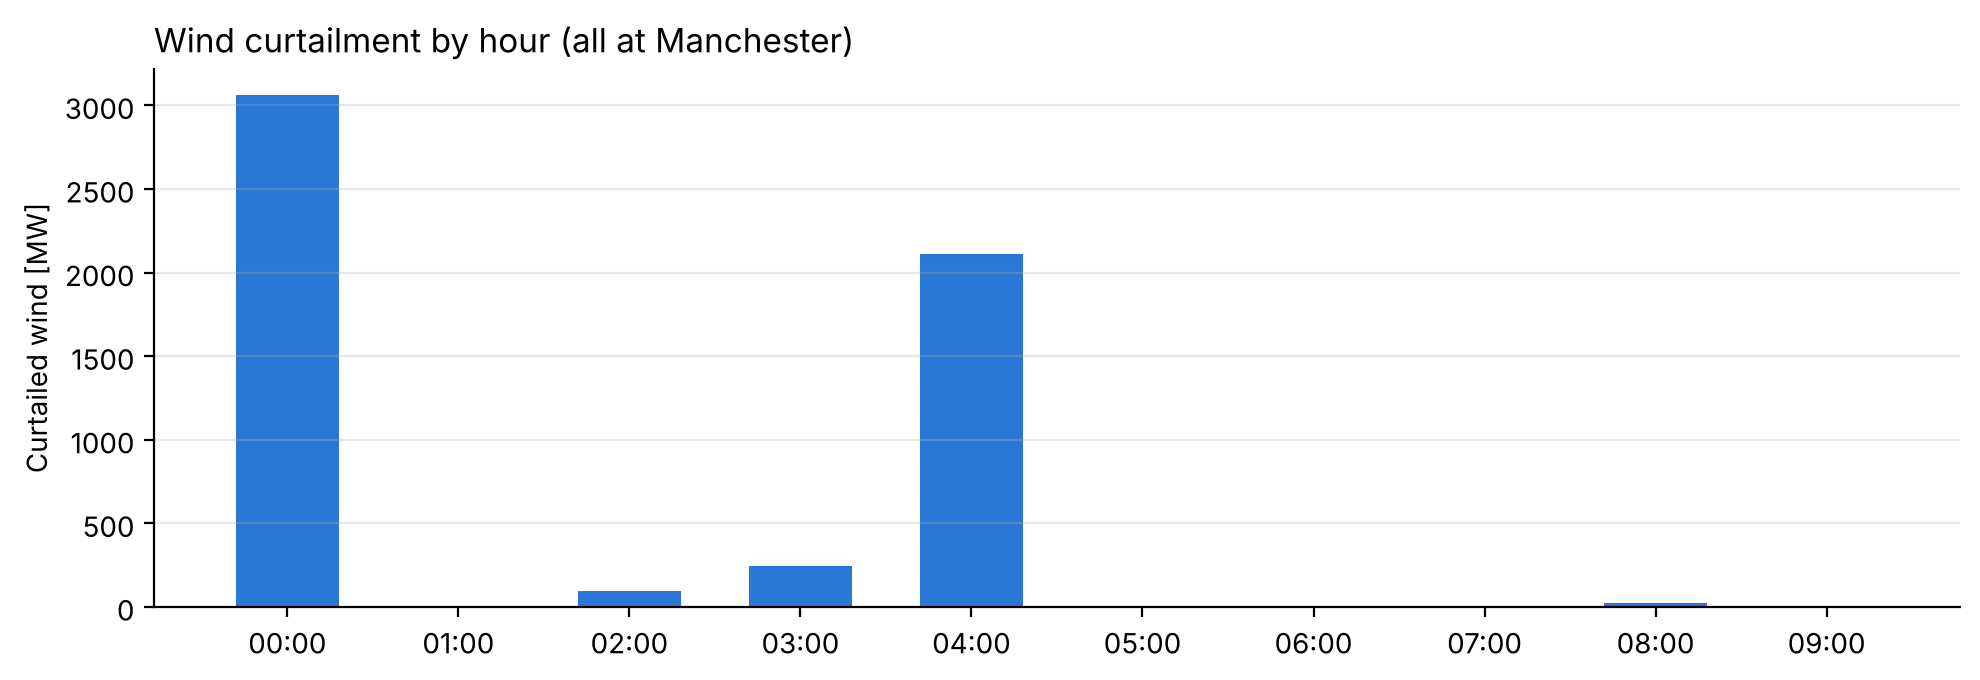

In [6]:
curt = (avail - n.generators_t.p[wind]).clip(lower=0)
curt.index = curt.index.strftime("%H:%M")
print(curt.round(1))
print(f"\nTotal curtailment: {curt.values.sum():,.0f} MWh "
      f"({curt.values.sum() / avail.values.sum():.1%} of available wind)")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(curt.index, curt["Manchester Wind"], color="#2a78d6", width=0.6, label="Manchester Wind")
ax.set_ylabel("Curtailed wind [MW]")
ax.set_title("Wind curtailment by hour (all at Manchester)", loc="left")
ax.grid(axis="y", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 2.3 How storage would help

The two problems sit at different times. There is surplus wind at 00:00 and 04:00, and there is a shortfall at 05:00 and 09:00, which is exactly when gas runs. Storage connects the two. It charges on wind that would otherwise be curtailed and discharges at 05:00 and 09:00, which:

* reduces curtailment,
* reduces how much gas has to be burnt and how much gas capacity has to be built, and frees up CO2 budget,
* lowers the peak prices, and reduces the amount of wind that has to be built only for the low-wind hours.

To show this, I added a battery (`StorageUnit`) at Frankfurt with 4 hours of storage, 90% charge and 90% discharge efficiency, a cyclic state of charge (it must end where it started) and an **illustrative capital cost of 200 EUR/MW**. That figure is my assumption, chosen on the same scale as the other capital costs in this toy model. It is not a market price. The goal is to show the direction of the effect, not to size a real battery.

In [7]:
b = load_network()
b.add("StorageUnit", "Battery", bus="Frankfurt", carrier="battery", p_nom_extendable=True,
      max_hours=4, capital_cost=200, efficiency_store=0.9, efficiency_dispatch=0.9,
      cyclic_state_of_charge=True)
b.optimize(solver_name=SOLVER, log_to_console=False)

wind_b = b.generators.index[b.generators.carrier == "wind"]
curt_b = (b.generators_t.p_max_pu[wind_b] * b.generators.p_nom_opt[wind_b] - b.generators_t.p[wind_b]).clip(lower=0)
comparison = pd.DataFrame({
    "without storage": [total_cost(n), n.generators.p_nom_opt["Frankfurt Gas"], n.generators_t.p["Frankfurt Gas"].sum(),
                        curt.values.sum(), n.generators.p_nom_opt[wind].sum(), 0],
    "with battery": [total_cost(b), b.generators.p_nom_opt["Frankfurt Gas"], b.generators_t.p["Frankfurt Gas"].sum(),
                     curt_b.values.sum(), b.generators.p_nom_opt[wind_b].sum(), b.storage_units.p_nom_opt["Battery"]],
}, index=["total cost [EUR]", "gas capacity [MW]", "gas energy [MWh]", "curtailment [MWh]",
          "wind capacity [MW]", "battery power [MW]"])
comparison.round(0)

,without storage,with battery
total cost [EUR],18440973.0,14927373.0
gas capacity [MW],982.0,1079.0
gas energy [MWh],1465.0,1465.0
curtailment [MWh],5549.0,0.0
wind capacity [MW],7292.0,6468.0
battery power [MW],0.0,3091.0


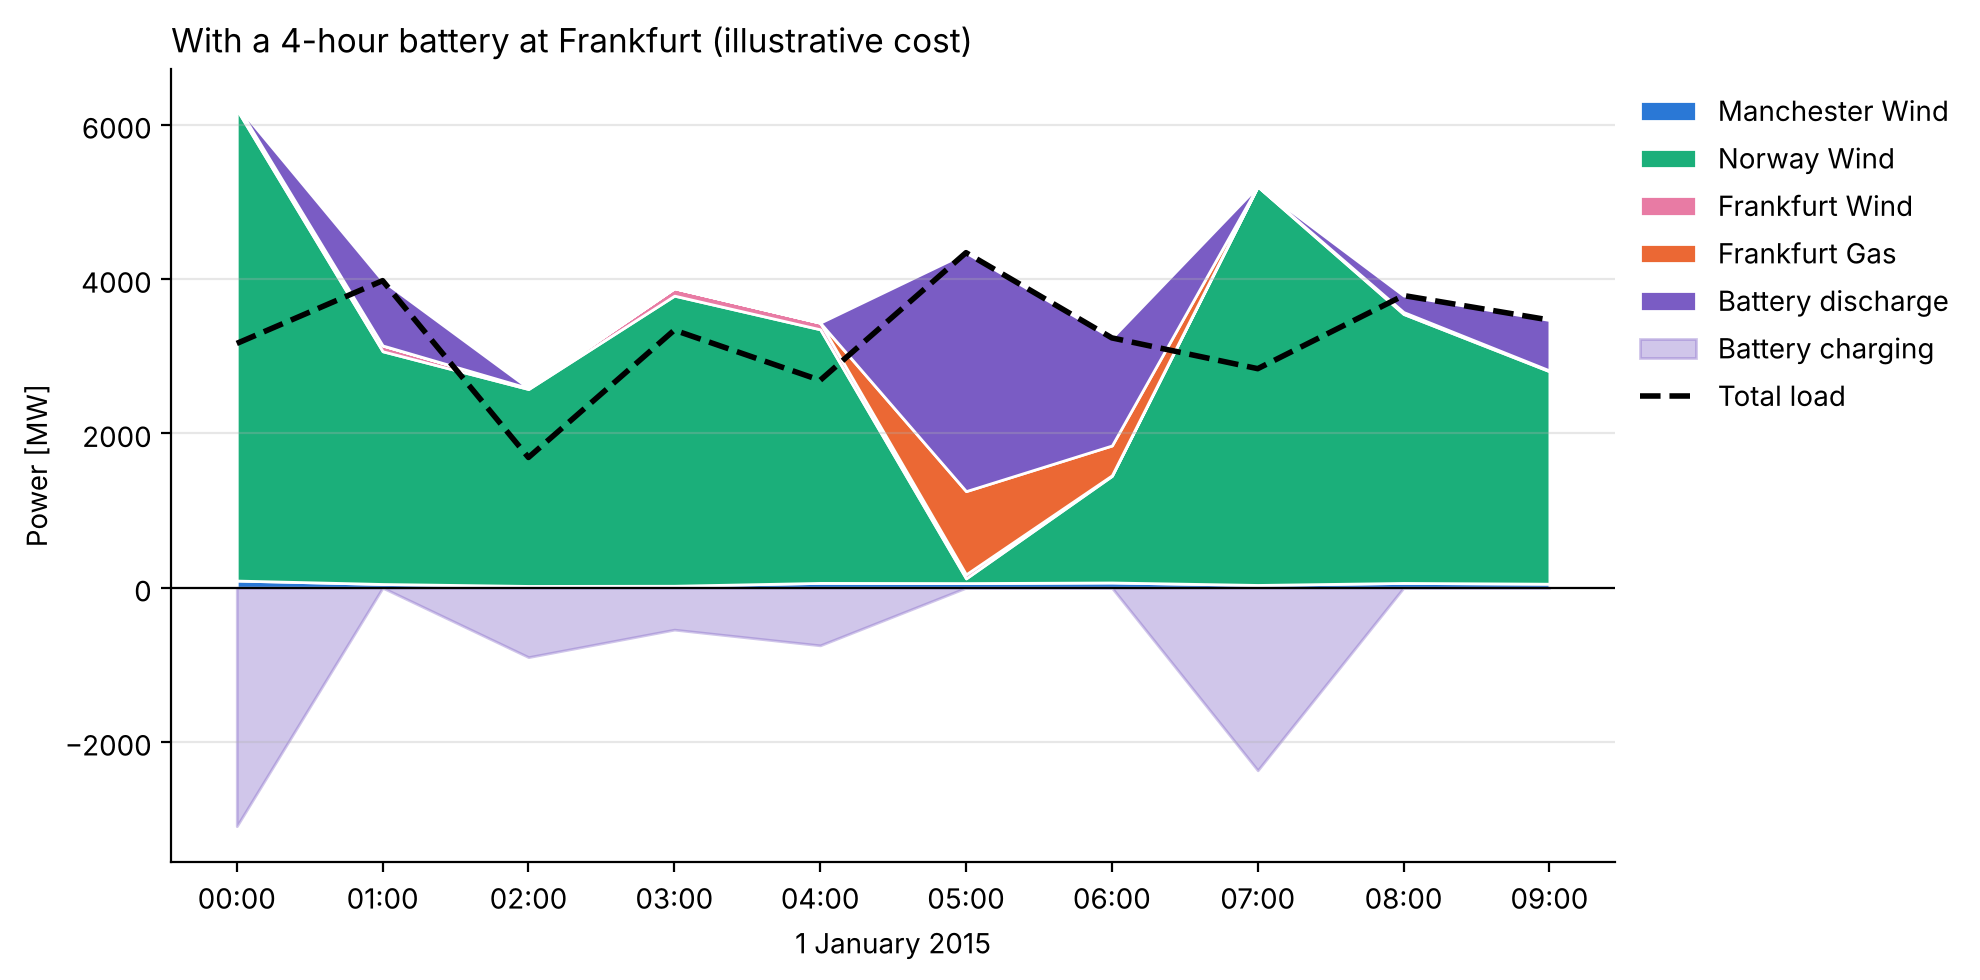

Battery dispatch [MW] (positive = discharging):
snapshot
2015-01-01 00:00:00   -3090.9
2015-01-01 01:00:00     840.1
2015-01-01 02:00:00    -899.5
2015-01-01 03:00:00    -543.1
2015-01-01 04:00:00    -746.7
2015-01-01 05:00:00    3090.9
2015-01-01 06:00:00    1394.9
2015-01-01 07:00:00   -2366.6
2015-01-01 08:00:00     214.6
2015-01-01 09:00:00     653.4
Name: Battery, dtype: float64


In [8]:
sto = b.storage_units_t.p["Battery"]
gen = b.generators_t.p.clip(lower=0)
gen = gen.loc[:, gen.sum() > 1]
gen["Battery discharge"] = sto.clip(lower=0)
cols = {**COLORS, "Battery discharge": "#7a5cc4"}
x = range(len(gen))
fig, ax = plt.subplots(figsize=(10, 5))
ax.stackplot(x, gen.T.values, labels=gen.columns, colors=[cols[c] for c in gen.columns],
             edgecolor="white", linewidth=1)
ax.fill_between(x, sto.clip(upper=0).values, 0, color="#7a5cc4", alpha=0.35, label="Battery charging")
ax.plot(x, b.loads_t.p_set.sum(axis=1).values, "k--", lw=2, label="Total load")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(list(x), gen.index.strftime("%H:%M")); ax.set_xlabel("1 January 2015")
ax.set_ylabel("Power [MW]")
ax.set_title("With a 4-hour battery at Frankfurt (illustrative cost)", loc="left")
ax.grid(axis="y", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout(); plt.show()
print("Battery dispatch [MW] (positive = discharging):")
print(sto.round(1))

With the battery, total system cost falls by about 19%, curtailment drops to zero, and about 800 MW less wind needs to be built. Gas energy stays at about 1,465 MWh. That is expected, because the CO2 cap already limits gas, and the battery does not make gas any cheaper than wind. Gas capacity actually rises slightly (to about 1,080 MW). With storage the optimiser builds mostly Norway Wind, which is almost still at 05:00 and 06:00, so gas now runs in those two hours and covers that dip together with the battery. The wind fleet also changes. Without storage, Manchester Wind is built big because it happens to blow during the 05:00 to 06:00 shortfall. Once storage can move energy between hours, *when* the wind blows matters less than *how much energy per euro* a site delivers. Norway Wind then becomes the best site, because it has the lowest capital cost per MWh of available energy.

Caveat: with only 10 hourly snapshots, a cyclic state of charge and illustrative costs, the size of these numbers should not be read literally. What carries over to a real system is the mechanism, where storage takes in surplus in windy hours and covers the low-wind hours.